# Lab 5: Frameworks and automatic differentiation

Run from the `lab05/` folder: `jupyter nbconvert --execute --to notebook --inplace lab5.ipynb` or `python src/lab5.py`. Code lives in `src/`.

| Task | Where |
|---|---|
| 1. `Value` node (data, grad, parents, local derivative rule) | `src/engine.py` → class `Value` |
| 2. add, mul, pow, ReLU build the graph in the forward pass | `src/engine.py` → `__add__`, `__mul__`, `__pow__`, `relu` |
| 3. backward: topological sort, seed grad = 1, reverse order, `+=` accumulation | `src/engine.py` → `Value.backward` + accumulation test |
| 4. check vs PyTorch autograd and numerical gradients, max abs diff < 1e-6 | Task 4 cell |
| 5. make_moons, 2→8→1, sigmoid, BCE, speed vs PyTorch, median of 5 runs | Task 5 cell |
| 6. graph inspection, eager vs `torch.compile` / `torch.jit.trace`, shape/dtype/contiguity, non-contiguous cost | Task 6 cell |


In [1]:
import sys, os, importlib, platform
sys.path.insert(0, 'src')
import torch
import lab5; importlib.reload(lab5)
lab5.RESULTS['env']={'python':platform.python_version(),'torch':torch.__version__,'platform':platform.platform(),'cpu_count':os.cpu_count()}
print(lab5.RESULTS['env'])

{'python': '3.11.18', 'torch': '2.15.0+cpu', 'platform': 'Linux-7.0.0-1020-azure-x86_64-with-glibc2.43', 'cpu_count': 4}


## Tasks 1–3: engine + gradient accumulation test
`x*x + x` uses `x` three times, so the correct gradient (7) is only obtained if gradients are **accumulated** (`+=`), not overwritten.

In [2]:
lab5.task3_accumulation_test()

# small graph printout: every op created a node with parents
from engine import Value
a, b, c = Value(2.0, label='a'), Value(-3.0, label='b'), Value(1.0, label='c')
out = ((a*b + c)**2).relu()
topo = out.backward()
for n in topo:
    print(f"{n._op or 'leaf':8} data={n.data:8.3f} grad={n.grad:8.3f} parents={len(n._prev)}")


=== Task 3: accumulation test ===
y = x*x + x at x=3 -> dy/dx = 7.0 (expected 7.0)
b = a + a          -> db/da = 2.0 (expected 2.0)
leaf     data=   1.000 grad= -10.000 parents=0
leaf     data=  -3.000 grad= -20.000 parents=0
leaf     data=   2.000 grad=  30.000 parents=0
*        data=  -6.000 grad= -10.000 parents=2
+        data=  -5.000 grad= -10.000 parents=2
**2      data=  25.000 grad=   1.000 parents=1
ReLU     data=  25.000 grad=   1.000 parents=1


## Task 4: `((a*b + c)**2).relu().sum()` — our engine vs PyTorch autograd vs central differences (h = 1e-6), float64

In [3]:
lab5.task4()


=== Task 4: ((a*b + c)**2).relu().sum() ===
forward: ours=8.215245855752  torch=8.215245855752
input    max|ours-torch|   max|ours-numeric|  max|torch-numeric|
a              0.000e+00           5.522e-10           5.522e-10
b              0.000e+00           6.854e-10           6.854e-10
c              0.000e+00           8.205e-10           8.205e-10
max absolute difference = 8.205e-10  ->  PASS (< 1e-6)
first 3 grads of a  ours : [ 0.14616512 -2.3175412   0.16799453]
first 3 grads of a  torch: [ 0.14616512 -2.3175412   0.16799453]


## Task 5: make_moons (100 samples), 2 → 8 (ReLU) → 1 (sigmoid), BCE, full-batch SGD lr = 0.5, 100 epochs
Both models start from **identical weights**, so their loss curves must coincide. Timing = median of 5 full training runs (PyTorch limited to 1 thread for fairness). The pure-Python run takes about 1 minute in total.


=== Task 5: make_moons, 2->8->1, sigmoid, BCE ===


loss epoch 1   ours=0.731302 torch=0.731302
loss epoch 100 ours=0.155390 torch=0.155390
max |loss_ours - loss_torch| over all epochs = 2.78e-16
train accuracy ours=0.930 torch=0.930


training time (100 epochs, 100 samples), median of 5 runs:
  our engine :   12715.9 ms   runs=[12675.0, 12715.9, 12861.9, 12334.9, 12789.5]
  PyTorch    :      28.9 ms   runs=[32.5, 28.9, 28.8, 28.7, 28.9]
  speed-up of PyTorch: 440.5x


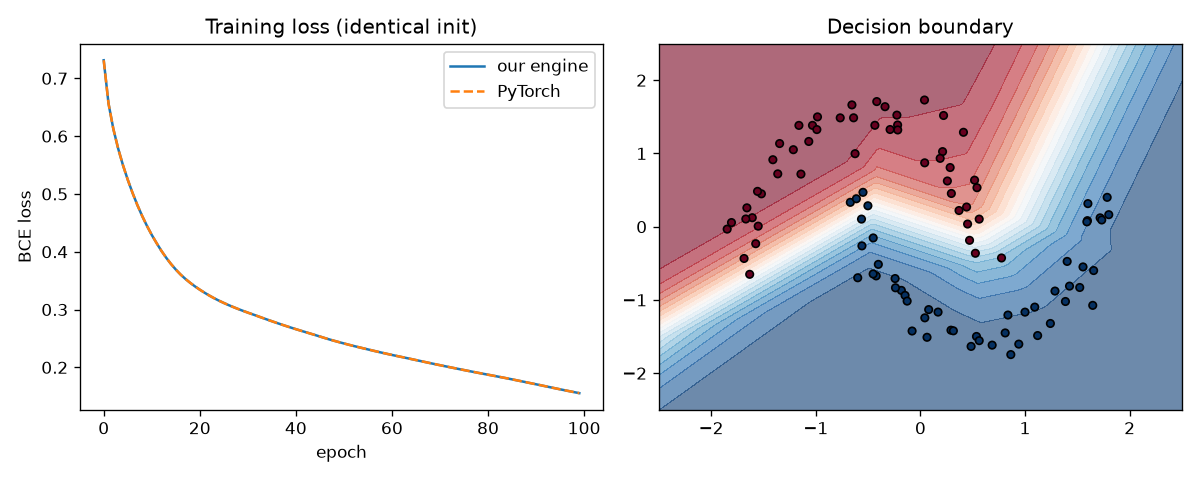

In [4]:
lab5.task5()
from IPython.display import Image, display
display(Image('results/task5_moons.png'))

## Task 6: PyTorch graph, eager vs compiled, tensor layout

In [5]:
lab5.task6()


=== Task 6: PyTorch graph, eager vs compiled, tensor layout ===

-- torch.fx graph (static view of forward) --
graph():
    %x : [num_users=2] = placeholder[target=x]
    %fc1 : [num_users=1] = call_module[target=fc1](args = (%x,), kwargs = {})
    %gelu : [num_users=2] = call_function[target=torch._C._nn.gelu](args = (%fc1,), kwargs = {})
    %sigmoid : [num_users=1] = call_function[target=torch.sigmoid](args = (%gelu,), kwargs = {})
    %mul : [num_users=1] = call_function[target=operator.mul](args = (%gelu, %sigmoid), kwargs = {})
    %add : [num_users=1] = call_function[target=operator.add](args = (%mul, %x), kwargs = {})
    %ln : [num_users=1] = call_module[target=ln](args = (%add,), kwargs = {})
    %fc2 : [num_users=1] = call_module[target=fc2](args = (%ln,), kwargs = {})
    %relu : [num_users=1] = call_method[target=relu](args = (%fc2,), kwargs = {})
    return relu
-- autograd graph (dynamic, built during eager forward) --
SumBackward0
  ReluBackward0
    AddmmBackward0
   


compiled with torch.compile (inductor); first call (compile) took 11.42 s



 batch    eager ms   compiled ms  speed-up
     1      0.0964        0.0612      1.57x
    64      0.2695        0.2392      1.13x
  1024      2.4465        2.4530      1.00x
  8192     35.0086       25.1602      1.39x


training step b=1024: eager 6.540 ms, compiled 7.833 ms, x0.83

-- contiguous vs non-contiguous (4096x4096 float32) --
contiguous           stride=(4096, 1) contiguous=True
transposed .t()      stride=(1, 4096) contiguous=False
strided [:, ::2]     stride=(4096, 2) contiguous=False
.t().contiguous()    stride=(4096, 1) contiguous=True
op                      contig ms   .t() ms   ratio


elementwise x*2+1           34.33     33.69    0.98x


row sum sum(dim=1)           1.15      2.36    2.05x


exp()                       23.50     23.55    1.00x


x*2+1 on [:, ::2]           18.00     19.20    1.07x


cost of making .t() contiguous (copy): 51.10 ms


## Summary of graded evidence

In [6]:
import json
R = lab5.RESULTS
print('Task 4: max abs diff =', f"{R['task4']['max_abs_diff']:.2e}", '->', 'PASS' if R['task4']['pass'] else 'FAIL')
t5 = R['task5']
print(f"Task 5: our engine {t5['median_ms_ours']:.0f} ms vs PyTorch {t5['median_ms_torch']:.1f} ms (x{t5['speedup']:.0f}), "
      f"acc {t5['acc'][0]:.2f}/{t5['acc'][1]:.2f}, max loss diff {t5['max_loss_diff']:.1e}")
t6 = R['task6']
print('Task 6:', t6['compile_mode'], f"(compile time {t6['compile_seconds']:.1f} s)")
for r in t6['eager_vs_compiled']:
    print(f"   batch {r['batch']:5d}: eager {r['eager_ms']:.4f} ms | compiled {r['compiled_ms']:.4f} ms | x{r['speedup']:.2f}")
for r in t6['noncontig']:
    print(f"   {r['op']:32} contiguous {r['contig_ms']:.2f} ms | non-contiguous {r['noncontig_ms']:.2f} ms | x{r['ratio']:.2f}")
json.dump(R, open('results/results.json','w'), indent=2, default=float)

Task 4: max abs diff = 8.21e-10 -> PASS
Task 5: our engine 12716 ms vs PyTorch 28.9 ms (x440), acc 0.93/0.93, max loss diff 2.8e-16
Task 6: torch.compile (inductor) (compile time 11.4 s)
   batch     1: eager 0.0964 ms | compiled 0.0612 ms | x1.57
   batch    64: eager 0.2695 ms | compiled 0.2392 ms | x1.13
   batch  1024: eager 2.4465 ms | compiled 2.4530 ms | x1.00
   batch  8192: eager 35.0086 ms | compiled 25.1602 ms | x1.39
   elementwise x*2+1                contiguous 34.33 ms | non-contiguous 33.69 ms | x0.98
   row sum sum(dim=1)               contiguous 1.15 ms | non-contiguous 2.36 ms | x2.05
   exp()                            contiguous 23.50 ms | non-contiguous 23.55 ms | x1.00
   x*2+1 on [:, ::2] (same numel)   contiguous 18.00 ms | non-contiguous 19.20 ms | x1.07


## Short note: when does compilation help?

*(Check that the sentences match the numbers printed above before submitting.)*

**What compilation does.** In eager mode PyTorch runs each operation as soon as Python reaches it: every op is a separate Python call, dispatcher lookup and kernel launch, and every intermediate tensor is written to and read back from memory. `torch.compile` (TorchDynamo + Inductor) captures the whole forward as a graph, then fuses chains of element-wise ops (here GELU → `h*sigmoid(h)` → `+x` → LayerNorm) into a few generated kernels and removes Python overhead. `torch.jit.trace` records one execution into a static TorchScript graph, which removes Python overhead and enables some fusion.

**When it helps**
- Models that run many times with the **same shapes** (inference serving, long training loops), so the one-off compile cost (seconds, see above) is amortised.
- Models with **many small / element-wise ops** that can be fused; memory-bound work benefits most.
- **Medium-to-large batches**, where fused kernels save real memory traffic.

**When it does not help (or hurts)**
- Short scripts, notebooks and debugging: compile time dominates; eager is easier to debug.
- Workloads dominated by **large matmuls** (already in optimised BLAS) — little left to optimise.
- **Changing shapes** or data-dependent Python control flow → graph breaks / recompilation; `jit.trace` even silently freezes one control-flow path.
- Very small inputs on CPU may show little or no gain because fixed overheads remain.

**Our autograd engine vs PyTorch.** Our engine is correct (gradients match to < 1e-6) but is much slower, because every scalar operation is a Python object and a Python closure; PyTorch works on whole tensors with vectorised C++ kernels, which is the main framework overhead lesson of Chapter 7.

**Non-contiguous tensors.** `.t()` and `[:, ::2]` are *views*: same storage, different strides, so `is_contiguous()` is False. Ops on them read memory with jumps (poor cache use / no straight vectorisation), so they are slower than on contiguous tensors; calling `.contiguous()` costs one copy but makes repeated later ops fast.
